In [42]:
# Import libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Logistic Regression model
from sklearn.linear_model import LogisticRegression

In [43]:
# Load dataset
df = pd.read_csv("/content/Telco-Customer-Churn.csv")

# Display first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [44]:
# Display dataset shape
print("Dataset Shape:", df.shape)

# Display dataset information
df.info()

# Display statistical summary
df.describe()

Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [45]:
# Check missing values
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [46]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [47]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Fill missing values with median
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

# Remove customerID column
df.drop("customerID", axis=1, inplace=True)

/tmp/ipykernel_757/1532989559.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)


In [48]:
# Display first rows after cleaning
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     5174
Yes    1869
Name: count, dtype: int64


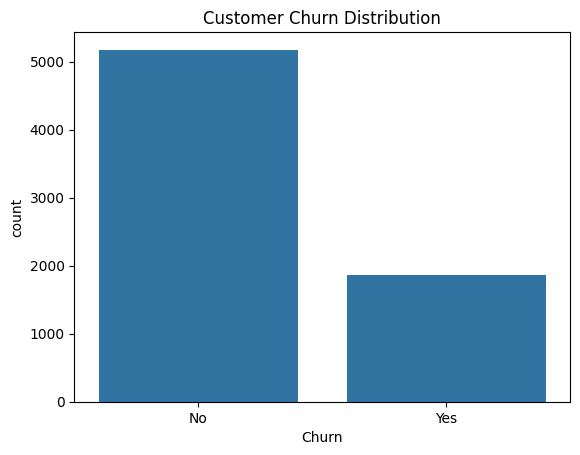

In [49]:
# Display target distribution
print(df["Churn"].value_counts())

# Plot target distribution
sns.countplot(x="Churn", data=df)

plt.title("Customer Churn Distribution")

plt.show()

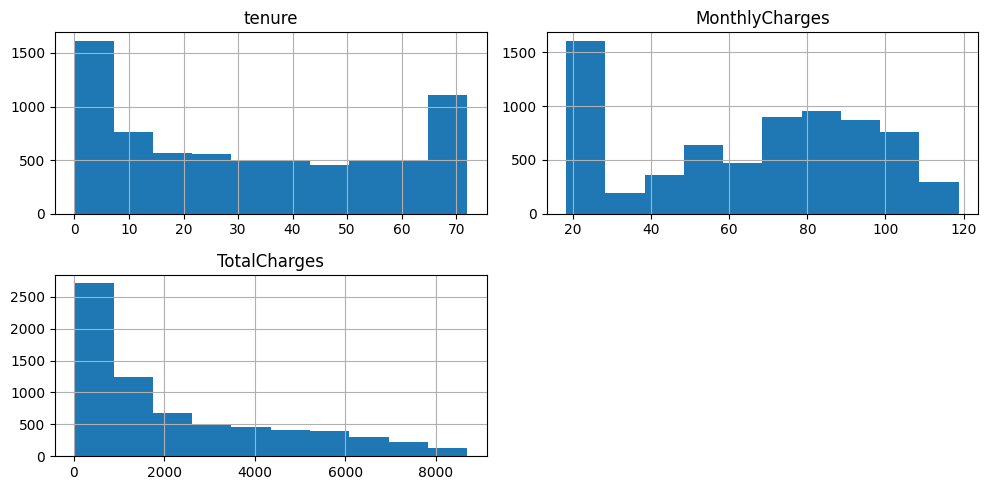

In [50]:
# Plot numerical feature distributions

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_features].hist(figsize=(10,5))

plt.tight_layout()

plt.show()

In [51]:
# Create Label Encoder
encoder = LabelEncoder()

# Encode categorical columns
for column in df.columns:

    if df[column].dtype == "object":

        df[column] = encoder.fit_transform(df[column])

In [52]:
# Display encoded dataset
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [53]:
# Split features and target
X = df.drop("Churn", axis=1)

y = df["Churn"]

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


In [54]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [55]:
# Scale features

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [56]:
# Create Logistic Regression model

model = LogisticRegression(max_iter=1000)

# Train model

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [57]:
# Calculate model accuracy

accuracy = model.score(X_test, y_test)

print("Accuracy:", accuracy)

Accuracy: 0.815471965933286


In [58]:
# Predict probabilities

probabilities = model.predict_proba(X_test)

print(probabilities[:5])

[[0.34843911 0.65156089]
 [0.94031194 0.05968806]
 [0.99507089 0.00492911]
 [0.42024024 0.57975976]
 [0.99426304 0.00573696]]


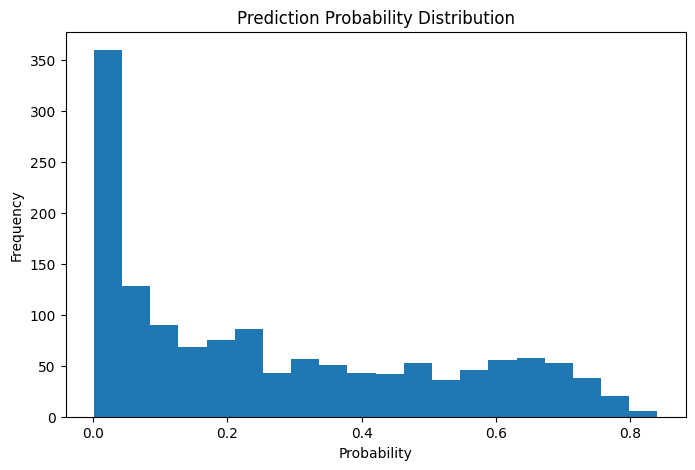

In [59]:
# Plot prediction probabilities

plt.figure(figsize=(8,5))

plt.hist(probabilities[:,1], bins=20)

plt.title("Prediction Probability Distribution")

plt.xlabel("Probability")

plt.ylabel("Frequency")

plt.show()

In [60]:
# Define Sigmoid function

def sigmoid(z):

    return 1 / (1 + np.exp(-z))

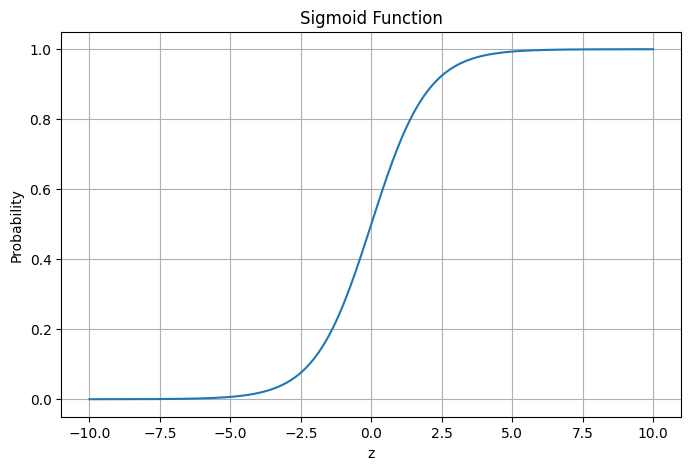

In [61]:
# Plot Sigmoid function

x = np.linspace(-10,10,200)

plt.figure(figsize=(8,5))

plt.plot(x, sigmoid(x))

plt.title("Sigmoid Function")

plt.xlabel("z")

plt.ylabel("Probability")

plt.grid(True)

plt.show()

In [62]:
# Define Softmax function

def softmax(x):

    exp = np.exp(x - np.max(x))

    return exp / np.sum(exp)

In [63]:
# Test Softmax

values = np.array([2.5,1.2,0.3])

print(softmax(values))

[0.72289072 0.1970107  0.08009858]


In [64]:
# Define Cross Entropy Loss

def cross_entropy(y_true, y_pred):

    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1-epsilon)

    loss = -(y_true*np.log(y_pred)+(1-y_true)*np.log(1-y_pred))

    return np.mean(loss)

In [65]:
# Calculate Cross Entropy Loss

loss = cross_entropy(y_test, probabilities[:,1])

print("Cross Entropy Loss:", loss)

Cross Entropy Loss: 0.39895344090427026


In [66]:
# Import PCA
from sklearn.decomposition import PCA

In [67]:
# Reduce features to 2 dimensions

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

# Display new shape
print(X_pca.shape)

(7043, 2)


In [68]:
# Split PCA data

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42
)

In [69]:
# Scale PCA features

scaler = StandardScaler()

X_train_pca = scaler.fit_transform(X_train_pca)

X_test_pca = scaler.transform(X_test_pca)

In [70]:
# Train Logistic Regression on PCA data

model_pca = LogisticRegression()

model_pca.fit(X_train_pca, y_train_pca)

LogisticRegression()

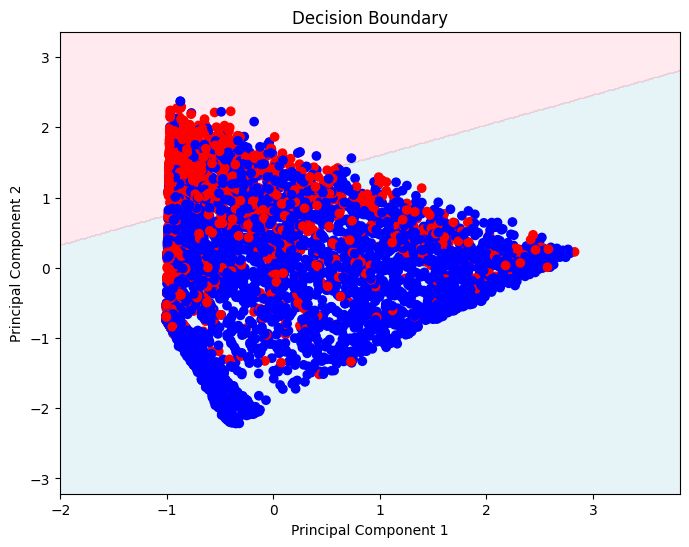

In [71]:
# Import mesh grid
from matplotlib.colors import ListedColormap

# Create mesh grid
x_min = X_train_pca[:,0].min() - 1
x_max = X_train_pca[:,0].max() + 1

y_min = X_train_pca[:,1].min() - 1
y_max = X_train_pca[:,1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

Z = model_pca.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap=ListedColormap(("lightblue","pink"))
)

plt.scatter(
    X_train_pca[:,0],
    X_train_pca[:,1],
    c=y_train_pca,
    cmap=ListedColormap(("blue","red"))
)

plt.title("Decision Boundary")

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.show()

In [72]:
# Display model coefficients

print("Coefficients:")

print(model.coef_)

print()

print("Intercept:")

print(model.intercept_)

Coefficients:
[[-0.02603593  0.06635631  0.03341652 -0.08308074 -1.30981968 -0.31050898
   0.06636946  0.17347073 -0.25150942 -0.13702641 -0.07257547 -0.2204667
  -0.01283433  0.03099895 -0.60320971  0.17560434  0.06214047  0.67127485
   0.5985363 ]]

Intercept:
[-1.69284647]


In [73]:
# Predict first five samples

prediction = model.predict(X_test[:5])

print(prediction)

[1 0 0 1 0]


In [74]:
# Compare actual and predicted values

comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": model.predict(X_test[:20])
})

comparison

,Actual,Predicted
0,1,1
1,0,0
2,0,0
3,1,1
4,0,0
5,1,0
6,0,0
7,0,0
8,1,0
9,1,0


In [75]:
# Save cleaned dataset

df.to_csv("Clean_Telco_Customer_Churn.csv", index=False)